# DSCI 552 — Homework 4

**Name:** Alan Nhan

**GitHub Username:** nhvn

**USC ID:** 3907-9934-60

### AI Use Disclosure

Generative AI was used to help organize the notebook, develop and debug Python code, understand classification methods, and check assignment requirements. The code was executed and the results were reviewed by the author.

**Example prompts used:**
- "How can I use logistic regression to classify bending and non-bending activities?"
- "How do I perform feature selection using RFE and cross-validation?"
- "Why are my logistic regression coefficients and p-values unstable?"
- "How can I handle class imbalance using case-control sampling?"
- "How do I compare L1 logistic regression with Naive Bayes classifiers?"
- "Can you reword this to sound more professional?"

### Data Preparation (Reused from HW3)

In [1]:
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

In [2]:
zip_path = Path("activity+recognition+system+based+on+multisensor+data+fusion+arem.zip")
extract_path = Path(".")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
data_path = Path(".")

activities = [
    "bending1", "bending2", "cycling",
    "lying", "sitting", "standing", "walking"
]

for activity in activities:
    folder = data_path / activity
    files = list(folder.glob("*.csv"))
    print(f"{activity}: {len(files)} files")

bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files


### Training and Testing Split (Reused from HW3)

In [4]:
train_files = []
test_files = []

for activity in activities:
    folder = data_path / activity
    test_count = 2 if activity in ["bending1", "bending2"] else 3

    for file in sorted(folder.glob("dataset*.csv")):
        dataset_num = int(file.stem.replace("dataset", ""))

        if dataset_num <= test_count:
            test_files.append(file)
        else:
            train_files.append(file)

print("Training instances:", len(train_files))
print("Testing instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Testing instances: 19
Total instances: 88


In [5]:
assert len(train_files) == 69
assert len(test_files) == 19
assert len(train_files) + len(test_files) == 88

print("Train/test split verified successfully!")

Train/test split verified successfully!


### Feature Extraction (Reused from HW3)

In [6]:
def extract_features(df):
    features = {}

    for i, col in enumerate(df.columns, start=1):
        series = df[col]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    return features

In [7]:
feature_rows = []

for file in train_files + test_files:
    rows = []

    with open(file, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            values = line.replace(",", " ").split()

            if len(values) == 7:
                try:
                    rows.append([float(v) for v in values])
                except ValueError:
                    continue

    df = pd.DataFrame(rows)

    assert df.shape[1] == 7, f"Unexpected columns: {file} {df.shape}"
    assert df.shape[0] in (479, 480), f"Unexpected rows: {file} {df.shape}"

    sensor_data = df.iloc[:, 1:7]

    features = extract_features(sensor_data)
    features["Instance"] = f"{file.parent.name}/{file.name}"

    feature_rows.append(features)

feature_df = pd.DataFrame(feature_rows)

feature_df = feature_df[
    ["Instance"] + [col for col in feature_df.columns if col != "Instance"]
]

print("Feature table shape:", feature_df.shape)
display(feature_df)

Feature table shape: (88, 43)


,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1/dataset3.csv,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
1,bending1/dataset4.csv,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
2,bending1/dataset5.csv,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
3,bending1/dataset6.csv,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
4,bending1/dataset7.csv,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,standing/dataset2.csv,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
84,standing/dataset3.csv,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
85,walking/dataset1.csv,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425
86,walking/dataset2.csv,12.50,45.00,33.509729,34.125,4.850923,30.50,36.7500,0.0,13.05,...,3.133564,14.6275,18.750,0.0,8.96,3.378479,3.085,1.787360,2.060,4.440


**Data Cleaning Note:** The file `sitting/dataset8.csv` contains 479 observations instead of 480. All available observations were retained for feature extraction without imputing the missing value.

In [8]:
assert feature_df.shape == (88, 43)
assert not feature_df.isnull().values.any()

print("Feature extraction verified successfully!")

Feature extraction verified successfully!


### 2(a)i — Binary Classification Scatter Plots

In [9]:
train_instances = {
    f"{file.parent.name}/{file.name}"
    for file in train_files
}

train_df = feature_df[
    feature_df["Instance"].isin(train_instances)
].copy()

train_df["Class"] = train_df["Instance"].apply(
    lambda x: 1 if x.startswith(("bending1/", "bending2/")) else 0
)

print("Training instances:", len(train_df))
print("Bending instances:", (train_df["Class"] == 1).sum())
print("Other instances:", (train_df["Class"] == 0).sum())

Training instances: 69
Bending instances: 9
Other instances: 60


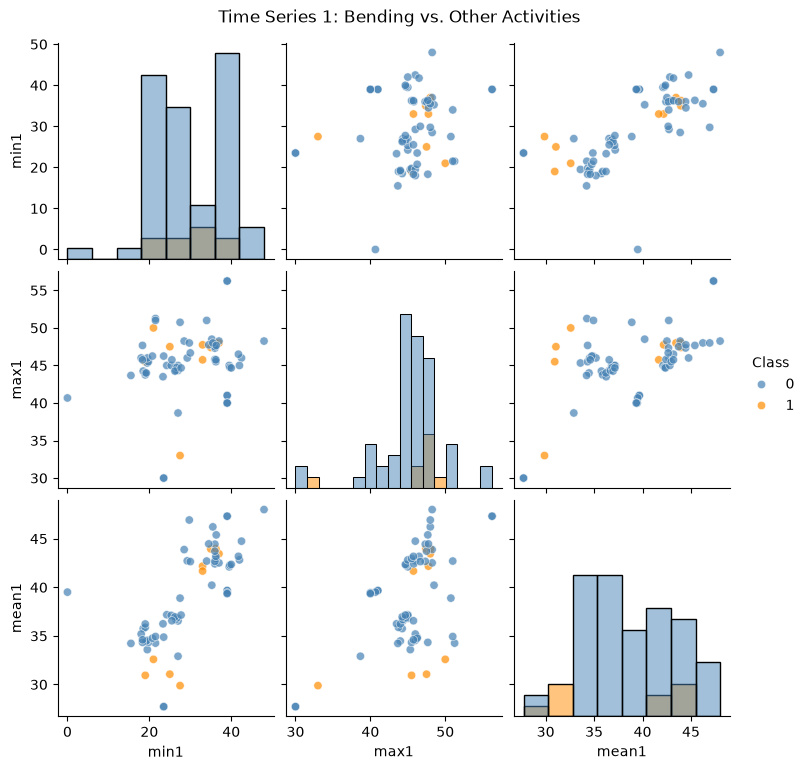

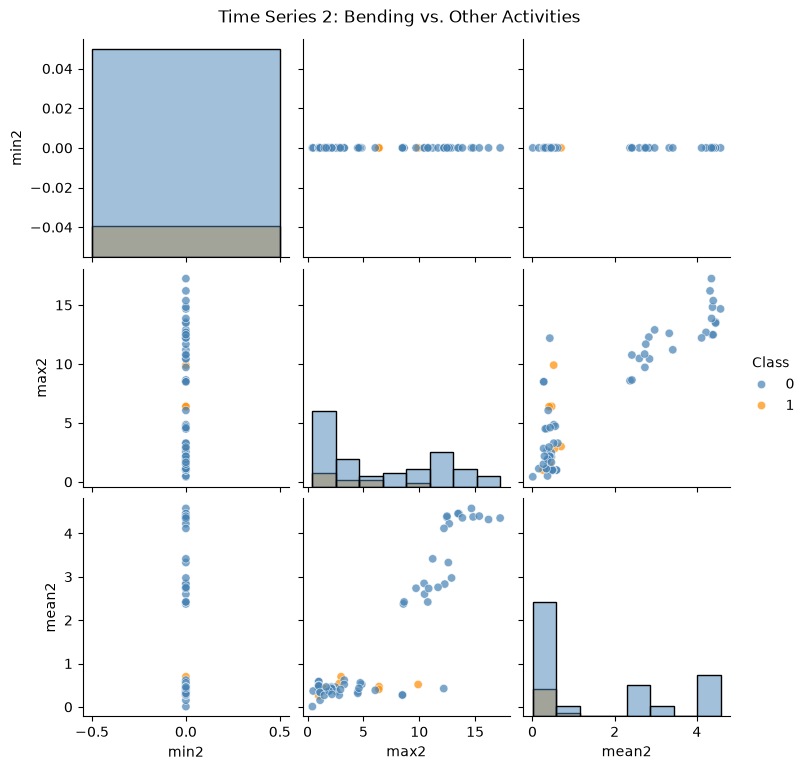

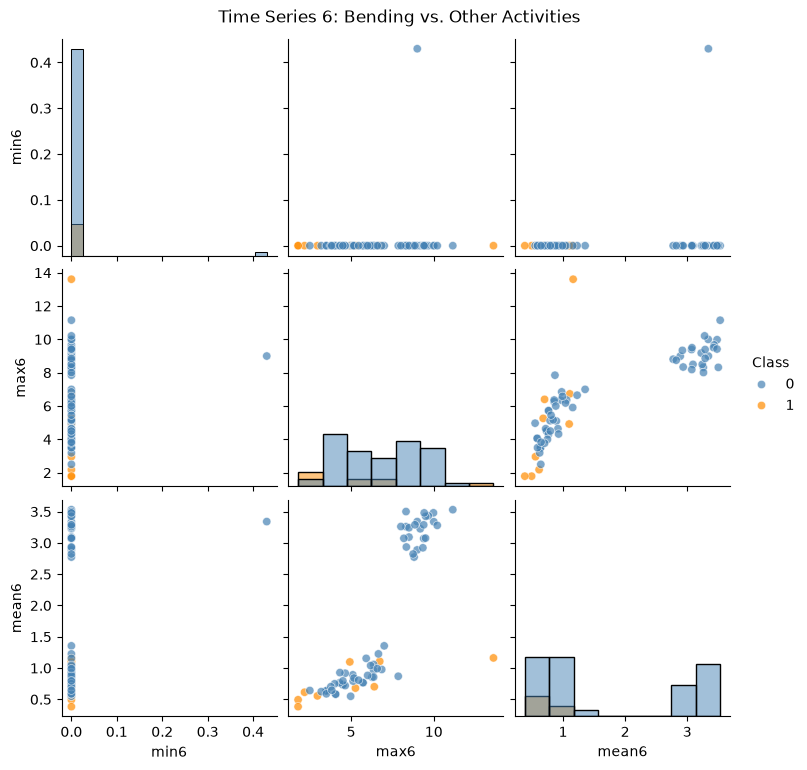

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_series = [1, 2, 6]

for i in selected_series:
    cols = [f"min{i}", f"max{i}", f"mean{i}"]

    sns.pairplot(
        train_df,
        vars=cols,
        hue="Class",
        palette={0: "steelblue", 1: "darkorange"},
        diag_kind="hist",
        plot_kws={"alpha": 0.7}
    )

    plt.suptitle(
        f"Time Series {i}: Bending vs. Other Activities",
        y=1.02
    )
    plt.show()

In [11]:
assert len(train_df) == 69
assert (train_df["Class"] == 1).sum() == 9
assert (train_df["Class"] == 0).sum() == 60

print("Binary classification data verified successfully!")

Binary classification data verified successfully!


### 2(a)ii — Scatter Plots After Splitting Time Series

In [12]:
def extract_split_features(df, l=2):
    features = {}

    for i, col in enumerate(df.columns, start=1):
        segments = np.array_split(df[col].to_numpy(), l)

        for j, segment in enumerate(segments, start=1):
            features[f"min{i}_{j}"] = np.min(segment)
            features[f"max{i}_{j}"] = np.max(segment)
            features[f"mean{i}_{j}"] = np.mean(segment)

    return features

In [13]:
split_rows = []

for file in train_files:
    rows = []

    with open(file, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            values = line.replace(",", " ").split()

            if len(values) == 7:
                try:
                    rows.append([float(v) for v in values])
                except ValueError:
                    continue

    df = pd.DataFrame(rows)
    sensor_data = df.iloc[:, 1:7]

    features = extract_split_features(sensor_data, l=2)
    features["Instance"] = f"{file.parent.name}/{file.name}"
    features["Class"] = (
        1 if file.parent.name in ["bending1", "bending2"] else 0
    )

    split_rows.append(features)

split_df = pd.DataFrame(split_rows)

print("Split feature table shape:", split_df.shape)
display(split_df.head())

Split feature table shape: (69, 38)


,min1_1,max1_1,mean1_1,min1_2,max1_2,mean1_2,min2_1,max2_1,mean2_1,min2_2,...,max5_2,mean5_2,min6_1,max6_1,mean6_1,min6_2,max6_2,mean6_2,Instance,Class
0,36.50,46.50,44.057167,35.00,47.40,43.851833,0.0,1.50,0.381042,0.0,...,38.25,34.883375,0.0,1.79,0.598250,0.0,1.50,0.388333,bending1/dataset3.csv,1
1,33.75,47.75,43.278875,33.00,46.00,41.080750,0.0,3.00,0.673292,0.0,...,38.50,30.965708,0.0,1.53,0.640958,0.0,2.18,0.586083,bending1/dataset4.csv,1
2,33.00,45.75,41.621208,39.25,43.67,41.734917,0.0,2.83,0.623083,0.0,...,36.00,29.635833,0.0,1.79,0.419083,0.0,1.50,0.347500,bending1/dataset5.csv,1
3,39.00,48.00,44.117042,37.00,46.50,42.792875,0.0,1.30,0.250042,0.0,...,26.00,22.850875,0.0,5.26,0.815417,0.0,4.06,0.543875,bending1/dataset6.csv,1
4,36.67,45.00,43.486208,36.25,48.00,44.452042,0.0,1.30,0.378667,0.0,...,26.00,21.882042,0.0,2.28,0.524875,0.0,2.96,0.585750,bending1/dataset7.csv,1


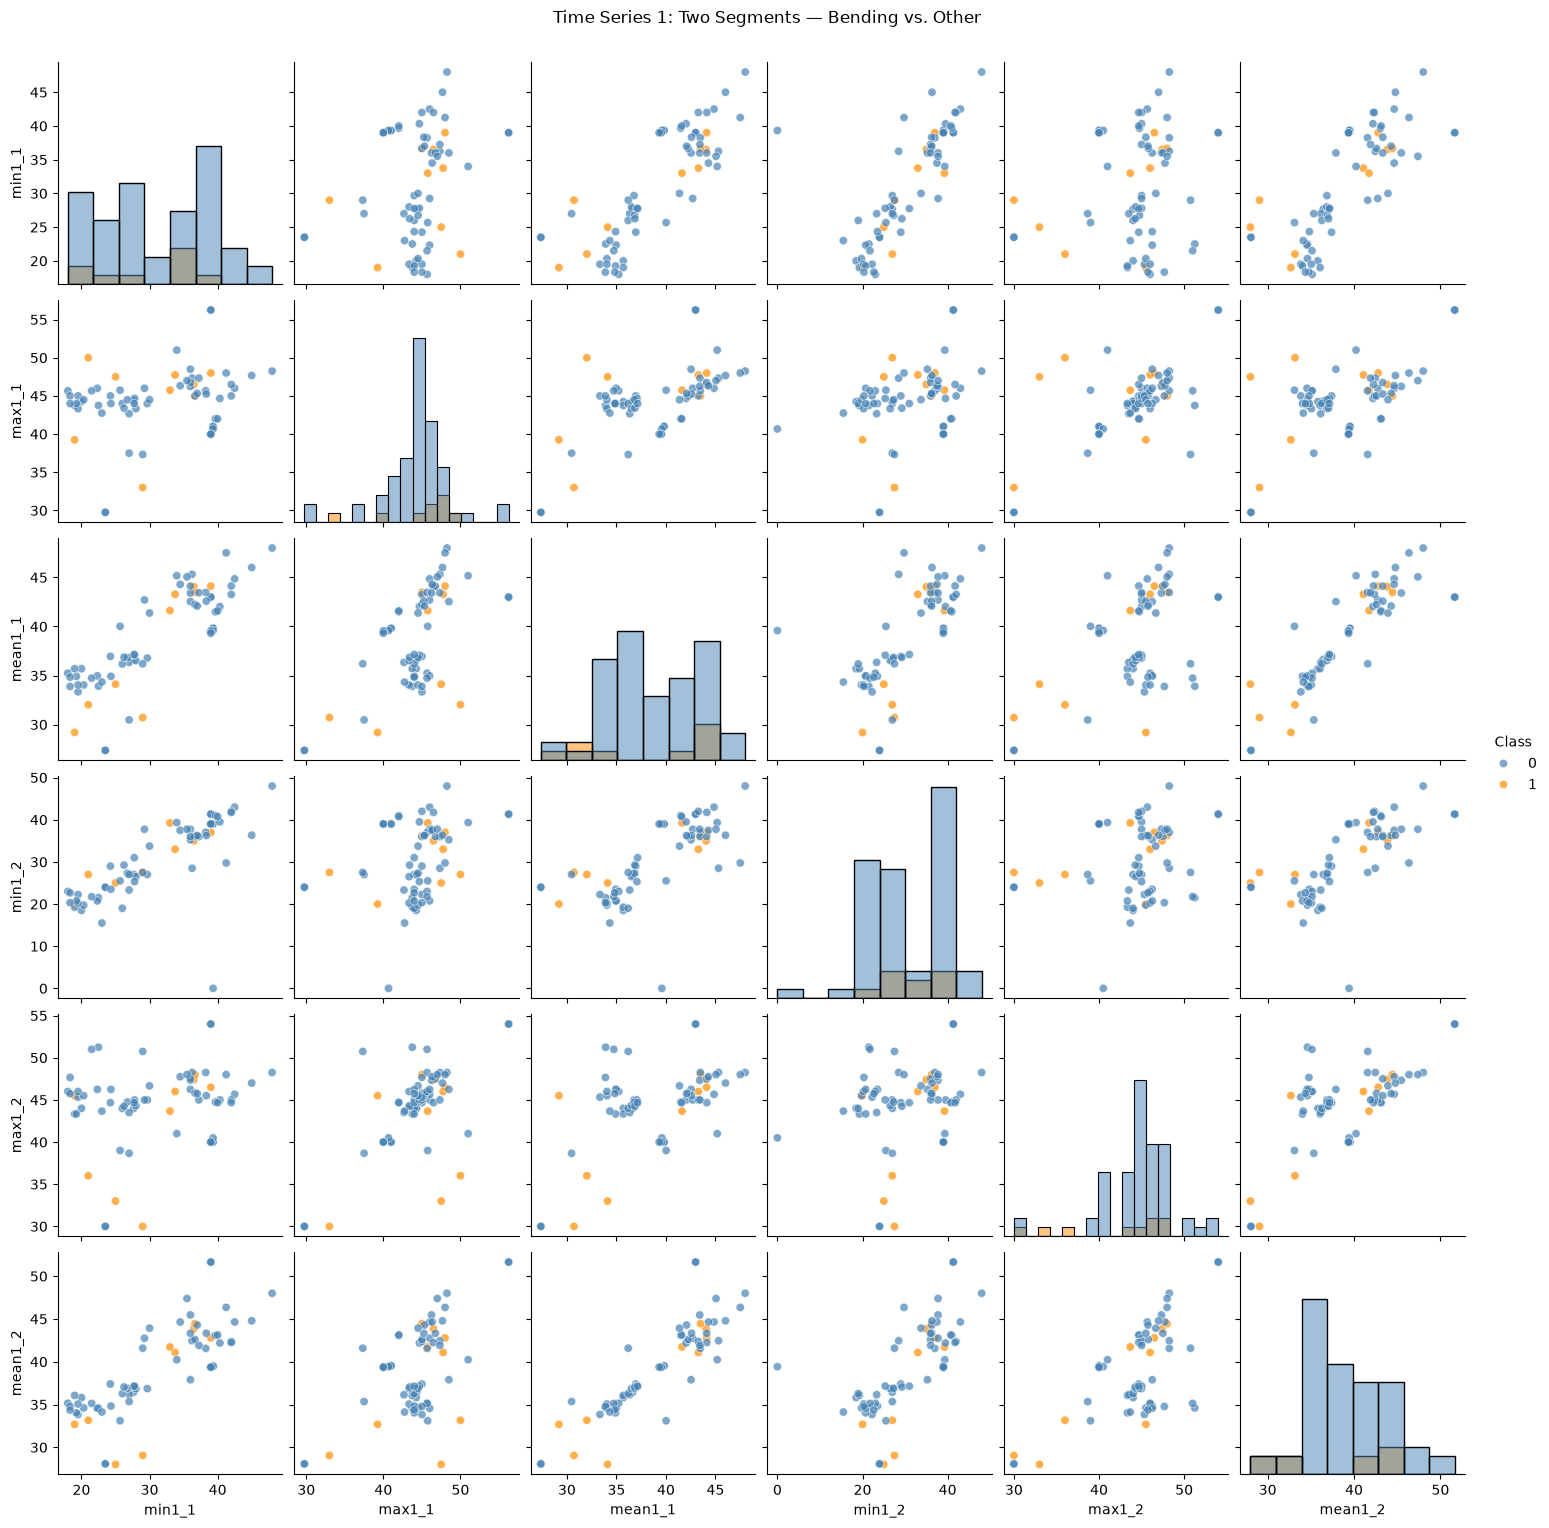

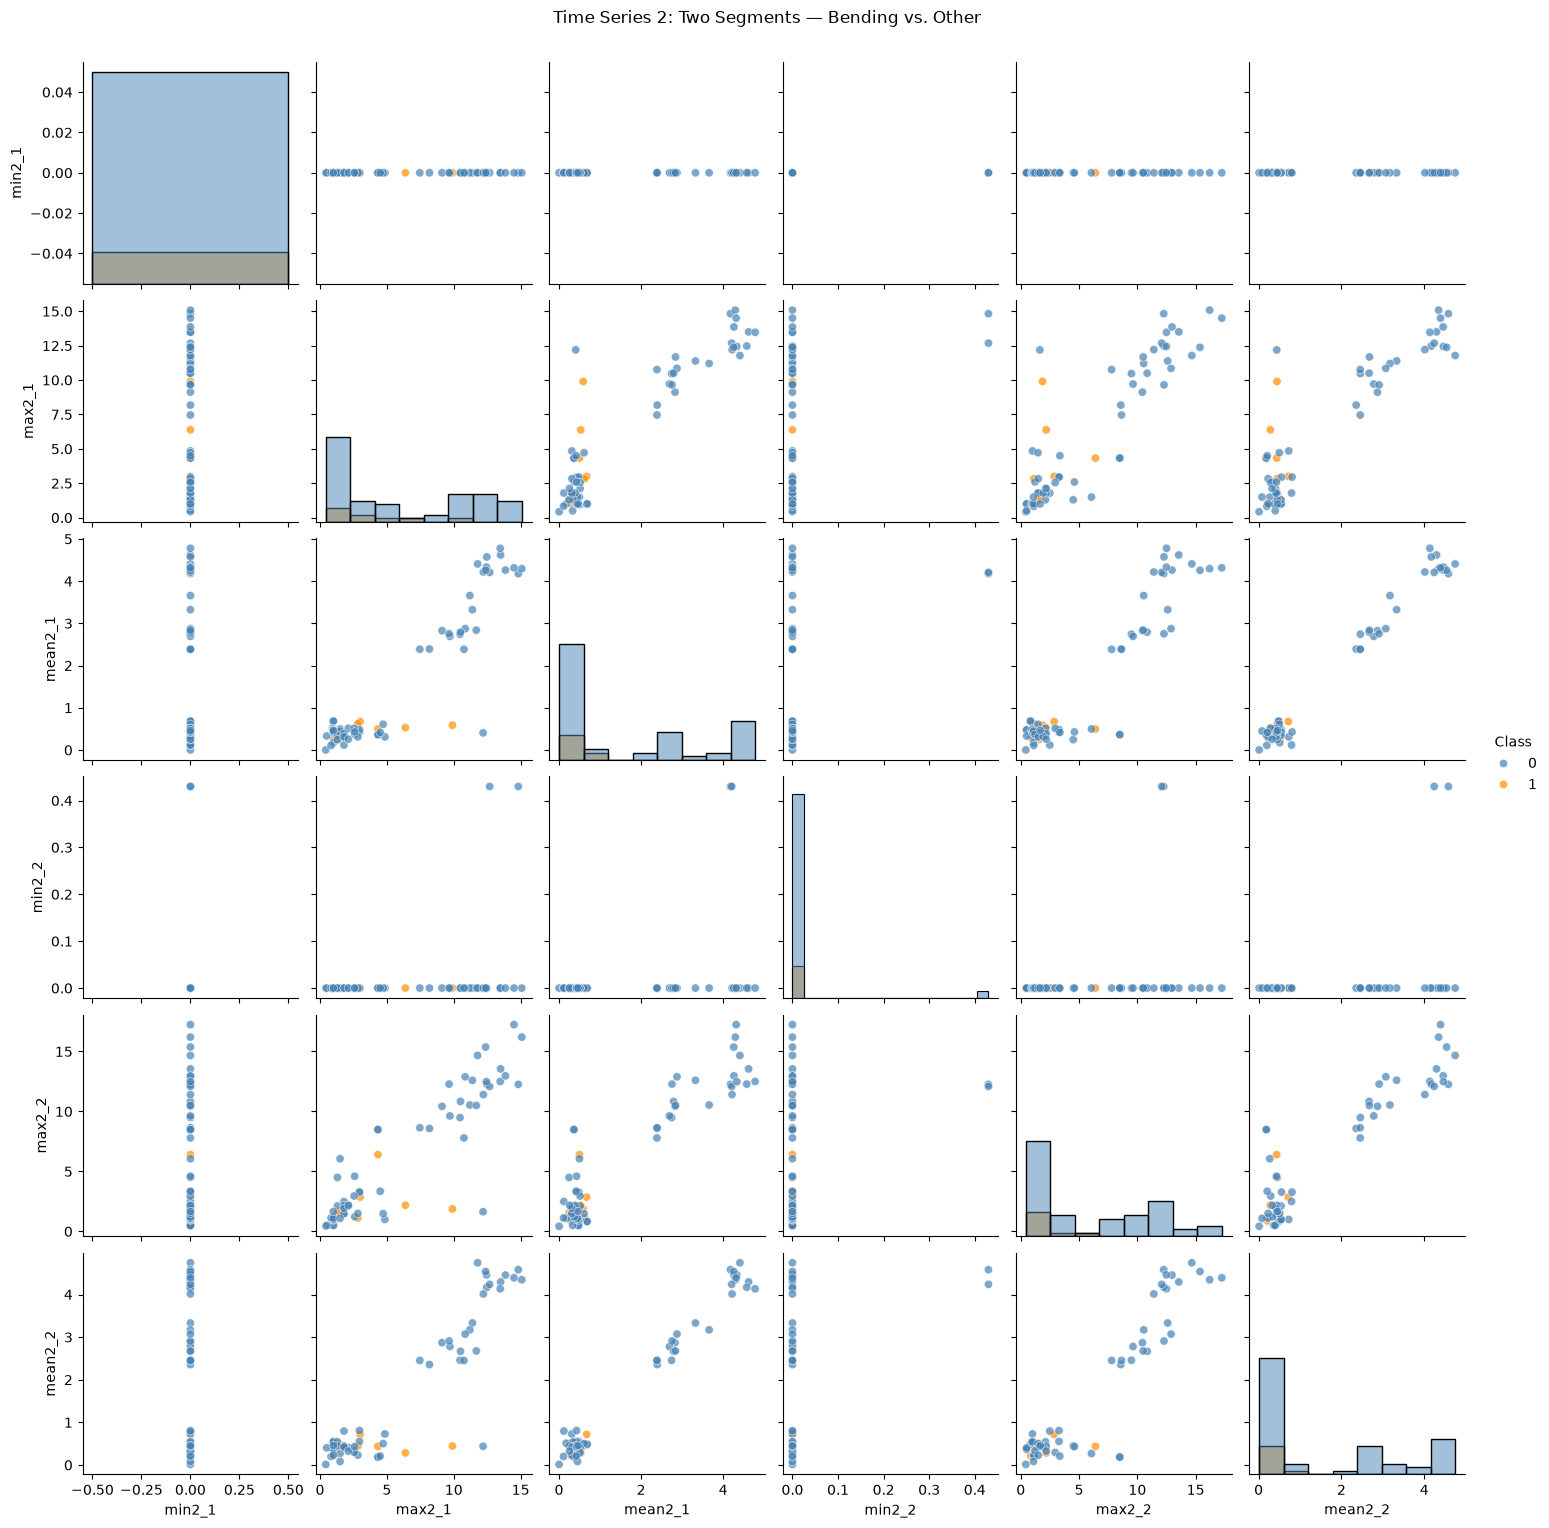

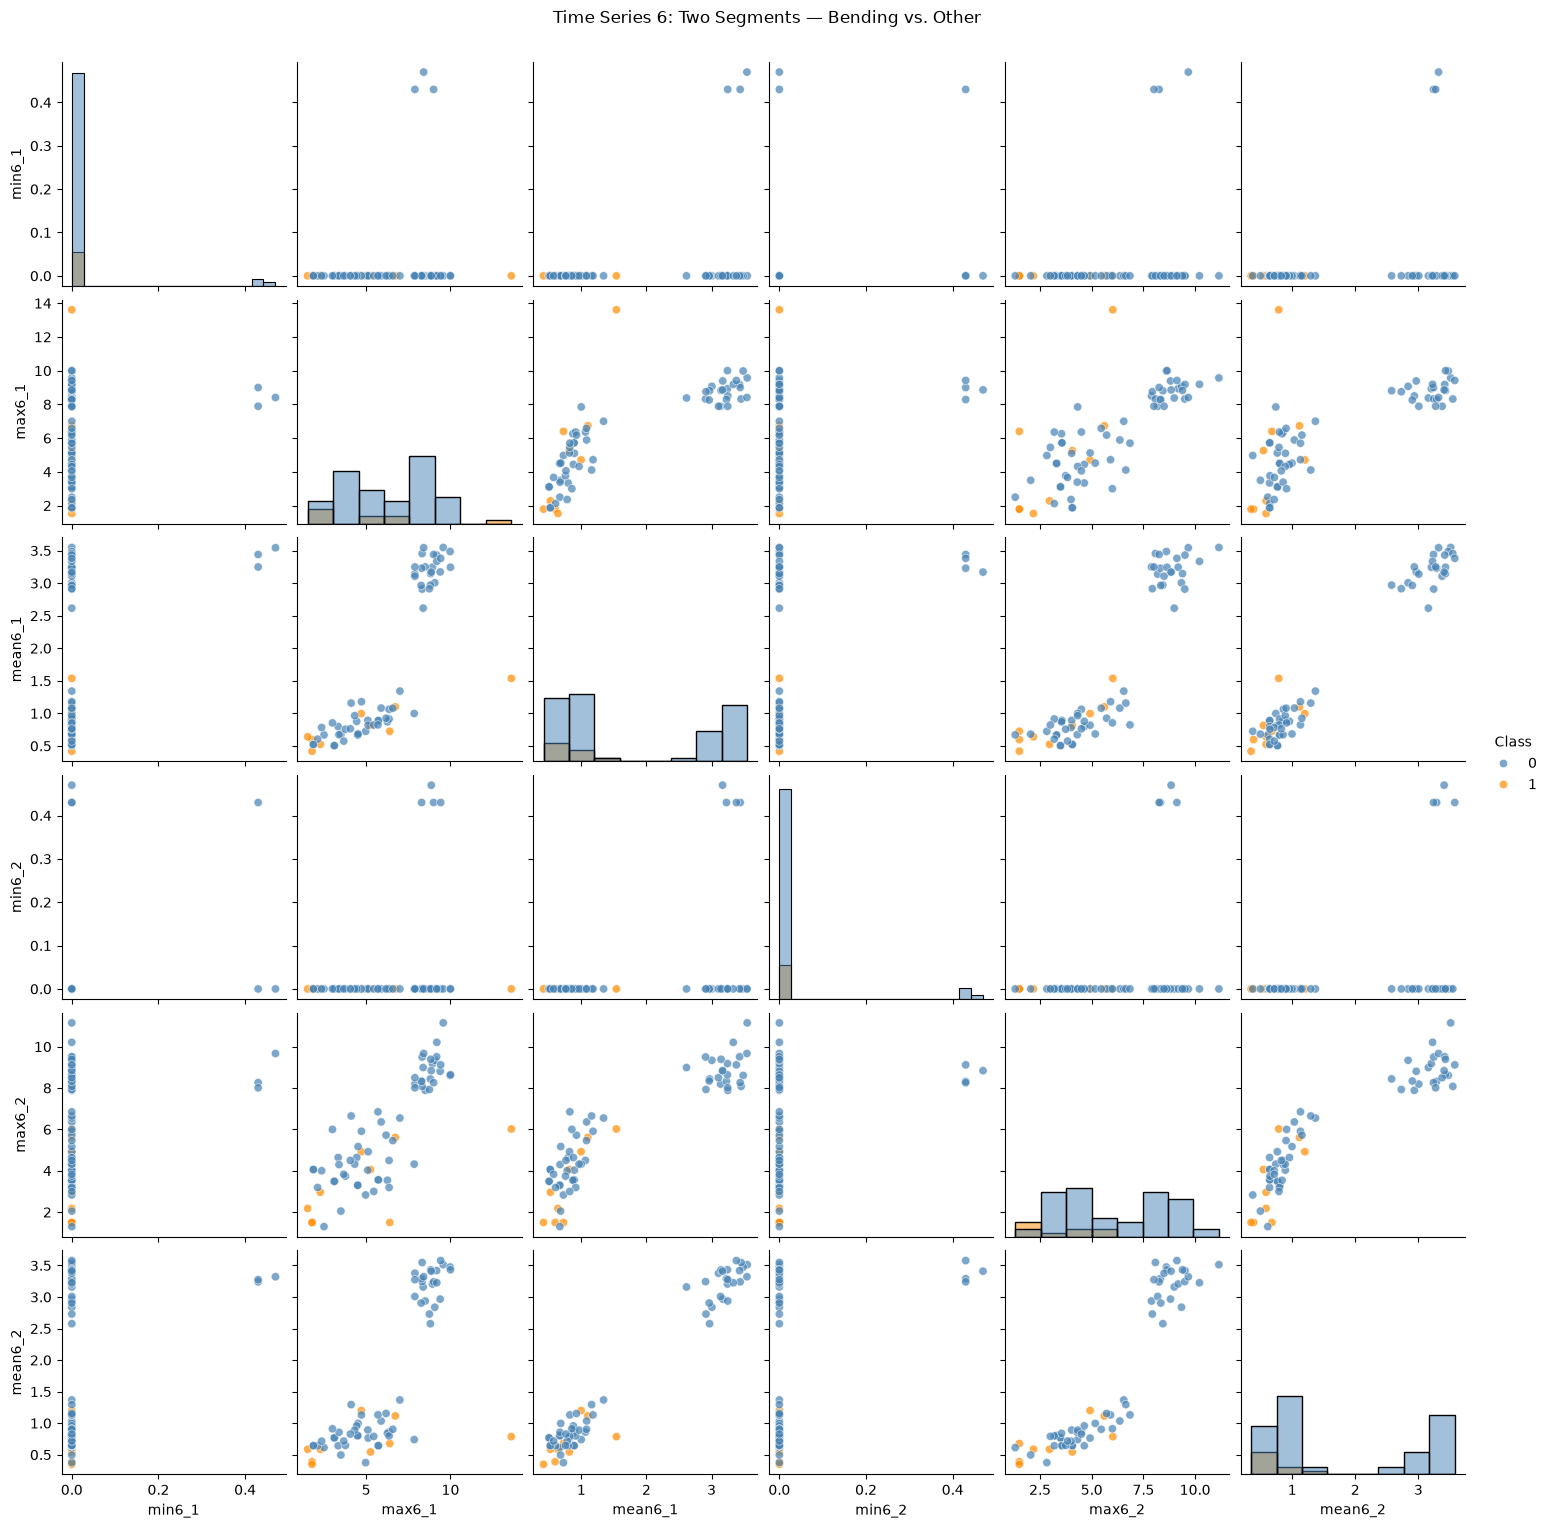

In [14]:
for i in [1, 2, 6]:
    cols = [
        f"min{i}_1", f"max{i}_1", f"mean{i}_1",
        f"min{i}_2", f"max{i}_2", f"mean{i}_2"
    ]

    sns.pairplot(
        split_df,
        vars=cols,
        hue="Class",
        palette={0: "steelblue", 1: "darkorange"},
        diag_kind="hist",
        plot_kws={"alpha": 0.7}
    )

    plt.suptitle(
        f"Time Series {i}: Two Segments — Bending vs. Other",
        y=1.02
    )
    plt.show()

In [15]:
assert split_df.shape == (69, 38)
assert (split_df["Class"] == 1).sum() == 9
assert (split_df["Class"] == 0).sum() == 60

print("Split feature extraction verified successfully!")

Split feature extraction verified successfully!


**Comparison with 2(a)i:**

After splitting the time series into two parts, the plots show some differences, but the overall patterns are still similar. There is still a lot of overlap between bending and non-bending activities, although some features seem to separate the two groups a little better.

### 2(a)iii — Logistic Regression with Cross-Validation and Feature Selection

In [16]:
def load_sensor_data(file):
    rows = []

    with open(file, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            values = line.replace(",", " ").split()

            if len(values) == 7:
                try:
                    rows.append([float(v) for v in values])
                except ValueError:
                    continue

    df = pd.DataFrame(rows)

    assert df.shape[1] == 7, f"Unexpected columns: {file}"
    assert df.shape[0] in (479, 480), f"Unexpected rows: {file}"

    return df.iloc[:, 1:7]

In [17]:
def extract_l_features(sensor_data, l):
    features = {}

    for i, col in enumerate(sensor_data.columns, start=1):
        segments = np.array_split(sensor_data[col].to_numpy(), l)

        for j, segment in enumerate(segments, start=1):
            features[f"min{i}_{j}"] = np.min(segment)
            features[f"max{i}_{j}"] = np.max(segment)
            features[f"mean{i}_{j}"] = np.mean(segment)
            features[f"median{i}_{j}"] = np.median(segment)
            features[f"std{i}_{j}"] = np.std(segment, ddof=1)
            features[f"q1_{i}_{j}"] = np.percentile(segment, 25)
            features[f"q3_{i}_{j}"] = np.percentile(segment, 75)

    return features

In [18]:
sensor_train = [load_sensor_data(file) for file in train_files]

y_train = np.array([
    1 if file.parent.name in ["bending1", "bending2"] else 0
    for file in train_files
])

X_by_l = {}

for l in range(1, 21):
    rows = [
        extract_l_features(sensor_data, l)
        for sensor_data in sensor_train
    ]

    X_by_l[l] = pd.DataFrame(rows)

print("Training instances:", len(y_train))
print("Number of segment configurations:", len(X_by_l))

for l in [1, 2, 5, 10, 20]:
    print(f"l={l}: {X_by_l[l].shape}")

Training instances: 69
Number of segment configurations: 20
l=1: (69, 42)
l=2: (69, 84)
l=5: (69, 210)
l=10: (69, 420)
l=20: (69, 840)


In [19]:
assert len(y_train) == 69
assert y_train.sum() == 9
assert len(X_by_l) == 20

for l, X in X_by_l.items():
    assert X.shape == (69, 42 * l)
    assert not X.isnull().values.any()

print("All training feature datasets verified successfully!")

All training feature datasets verified successfully!


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

In [21]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configured successfully!")

Cross-validation configured successfully!


In [22]:
def create_pipeline(p):
    selector_model = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=1000
    )

    classifier = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=1000
    )

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=selector_model,
            n_features_to_select=p,
            step=0.2
        )),
        ("classifier", classifier)
    ])

In [23]:
X = X_by_l[1]
p = 3

pipeline = create_pipeline(p)

scores = cross_val_score(
    pipeline,
    X,
    y_train,
    cv=cv,
    scoring="accuracy",
    error_score="raise"
)

print("Cross-validation scores:", scores)
print("Mean CV accuracy:", scores.mean())

Cross-validation scores: [1.         1.         0.92857143 1.         1.        ]
Mean CV accuracy: 0.9857142857142858


In [24]:
assert len(scores) == 5
assert np.all((scores >= 0) & (scores <= 1))

print("Cross-validation pipeline verified successfully!")

Cross-validation pipeline verified successfully!


In [25]:
p_candidates = list(range(1, 21))
cv_results = []

for l in range(1, 21):
    X = X_by_l[l]

    for p in p_candidates:
        pipeline = create_pipeline(p)

        scores = cross_val_score(
            pipeline,
            X,
            y_train,
            cv=cv,
            scoring="accuracy",
            error_score="raise"
        )

        cv_results.append({
            "l": l,
            "p": p,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Completed l = {l}/20")

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        ["Mean CV Accuracy", "l", "p"],
        ascending=[False, True, True]
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20


,l,p,Mean CV Accuracy,CV Std
2,1,3,0.985714,0.028571
14,1,15,0.985714,0.028571
18,1,19,0.985714,0.028571
40,3,1,0.985714,0.028571
194,10,15,0.985714,0.028571
3,1,4,0.971429,0.034993
12,1,13,0.971429,0.034993
13,1,14,0.971429,0.034993
15,1,16,0.971429,0.034993
16,1,17,0.971429,0.034993


In [26]:
best_row = cv_results_df.sort_values(
    ["Mean CV Accuracy", "l", "p"],
    ascending=[False, True, True]
).iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["p"])

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_row["Mean CV Accuracy"])

Best l: 1
Best p: 3
Best CV accuracy: 0.9857142857142858


In [27]:
assert len(cv_results_df) == 400
assert 1 <= best_l <= 20
assert best_p in p_candidates
assert 0 <= best_row["Mean CV Accuracy"] <= 1

print("Model selection verified successfully!")

Model selection verified successfully!


**Correct vs. Incorrect Cross-Validation**

The correct method is to scale the data and select features separately within each training fold, then test the model on the validation fold.

The incorrect method is to scale or select features using the entire dataset before cross-validation. This can cause data leakage and make the accuracy seem higher than it actually is.

I used stratified 5-fold cross-validation to keep the proportion of bending and non-bending activities similar across folds.

### 2(a)iv — Training Evaluation and Logistic Regression Coefficients

In [28]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

X_train_best = X_by_l[best_l]

final_pipeline = create_pipeline(best_p)
final_pipeline.fit(X_train_best, y_train)

y_train_pred = final_pipeline.predict(X_train_best)
y_train_prob = final_pipeline.predict_proba(X_train_best)[:, 1]

print("Training accuracy:", accuracy_score(y_train, y_train_pred))
print("Training AUC:", roc_auc_score(y_train, y_train_prob))

Training accuracy: 1.0
Training AUC: 1.0


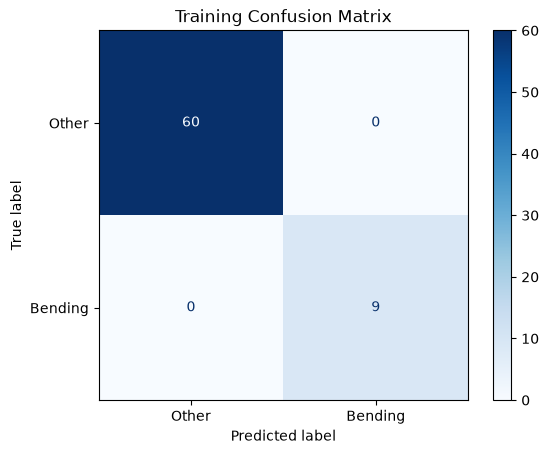

In [29]:
cm = confusion_matrix(y_train, y_train_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

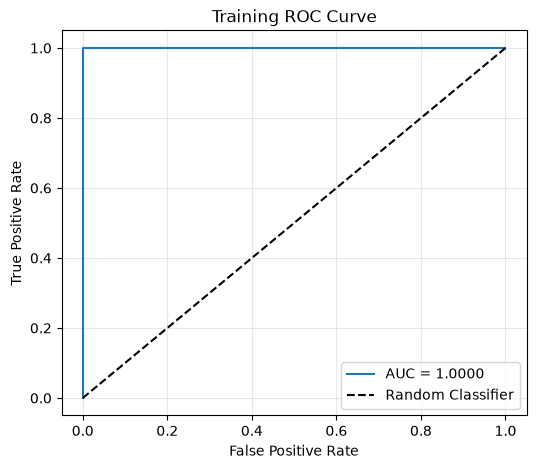

Training AUC: 1.0000


In [30]:
fpr, tpr, thresholds = roc_curve(y_train, y_train_prob)
train_auc = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f"AUC = {train_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Training AUC: {train_auc:.4f}")

In [31]:
selected_mask = final_pipeline.named_steps["rfe"].support_

selected_features = X_train_best.columns[selected_mask]

classifier = final_pipeline.named_steps["classifier"]

coef_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": classifier.coef_[0]
})

print("Intercept:", classifier.intercept_[0])
display(coef_df)

Intercept: -57.76732442492252


,Feature,Coefficient
0,min5_1,52.955855
1,max5_1,39.045879
2,q1_6_1,-4.164768


In [32]:
import statsmodels.api as sm

X_scaled = final_pipeline.named_steps["scaler"].transform(
    final_pipeline.named_steps["imputer"].transform(X_train_best)
)

X_selected = X_scaled[:, selected_mask]
X_selected_sm = sm.add_constant(X_selected, has_constant="add")

logit_model = sm.Logit(y_train, X_selected_sm)
logit_result = logit_model.fit(disp=False, maxiter=100)

pvalue_df = pd.DataFrame({
    "Feature": ["Intercept"] + list(selected_features),
    "Coefficient": logit_result.params,
    "P-value": logit_result.pvalues
})

display(pvalue_df)

/Users/alannhan/Desktop/HW4/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Feature,Coefficient,P-value
0,Intercept,-186.548953,0.997873
1,min5_1,171.645895,0.997880
2,max5_1,127.240137,0.997882
3,q1_6_1,-9.890109,0.999617


In [33]:
print("Converged:", logit_result.mle_retvals["converged"])
print("Iterations:", logit_result.mle_retvals["iterations"])

print("\nModel summary:")
print(logit_result.summary())

Converged: False
Iterations: 100

Model summary:
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        13:52:14   Log-Likelihood:            -2.0318e-08
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -186.5490      7e+04     -0.003      0.998   -1.37e+05    1.37e+05
x1           171.6459   6.46e+04      0.003      0.998   -1.26e+05    1.27e+05
x2 

**Model Convergence Note:**

The logistic regression model did not converge because the training data showed complete separation. As a result, the coefficients and p-values are unstable and should not be considered reliable, even though the model fits the training data well.

In [34]:
assert cm.shape == (2, 2)
assert len(selected_features) == best_p
assert len(y_train_pred) == 69
assert 0 <= train_auc <= 1

print("Training evaluation verified successfully!")

Training evaluation verified successfully!


### 2(a)v — Testing the Classifier on the Test Set

In [35]:
sensor_test = [load_sensor_data(file) for file in test_files]

X_test = pd.DataFrame([
    extract_l_features(sensor_data, best_l)
    for sensor_data in sensor_test
])

y_test = np.array([
    1 if file.parent.name in ["bending1", "bending2"] else 0
    for file in test_files
])

X_test = X_test[X_train_best.columns]

print("Test feature shape:", X_test.shape)
print("Test instances:", len(y_test))
print("Bending instances:", y_test.sum())
print("Other instances:", len(y_test) - y_test.sum())

Test feature shape: (19, 42)
Test instances: 19
Bending instances: 4
Other instances: 15


In [36]:
y_test_pred = final_pipeline.predict(X_test)
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
cv_accuracy = best_row["Mean CV Accuracy"]

print(f"Cross-validation accuracy: {cv_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Difference: {test_accuracy - cv_accuracy:.4f}")

Cross-validation accuracy: 0.9857
Test accuracy: 0.8947
Difference: -0.0910


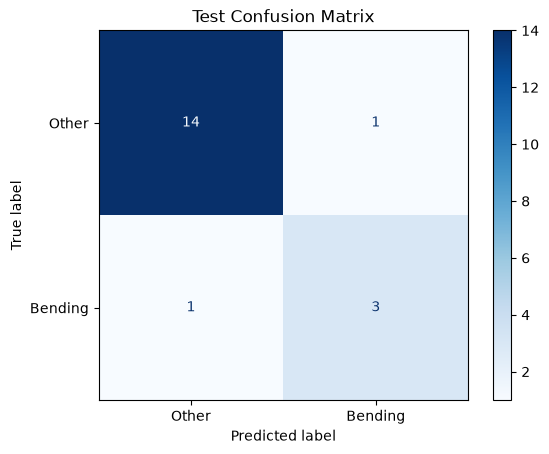

In [37]:
test_cm = confusion_matrix(y_test, y_test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Test Confusion Matrix")
plt.show()

In [38]:
assert X_test.shape == (19, 42 * best_l)
assert len(y_test) == 19
assert y_test.sum() == 4
assert list(X_test.columns) == list(X_train_best.columns)
assert len(y_test_pred) == 19
assert 0 <= test_accuracy <= 1

print("Test evaluation verified successfully!")

Test evaluation verified successfully!


**Comparison of Test and Cross-Validation Accuracy**

The model achieved 98.57% accuracy during cross-validation and 89.47% on the test set. The test accuracy is about 9.1 percentage points lower, suggesting that the model performs slightly worse on unseen data but still has reasonably good classification performance.

### 2(a)vi — Complete Separation

Yes, the classes appear to be completely separated in the training data. The logistic regression model failed to converge after 100 iterations, and the output confirmed complete separation. This caused unstable coefficient estimates and unreliable p-values, even though the model classified the training data well.

### 2(a)vii — Class Imbalance and Case-Control Sampling

In [39]:
from sklearn.utils import resample

X = X_by_l[best_l].reset_index(drop=True)
y = pd.Series(y_train)

bending_idx = y[y == 1].index
other_idx = y[y == 0].index

other_sample = resample(
    other_idx,
    replace=False,
    n_samples=len(bending_idx),
    random_state=42
)

balanced_idx = np.concatenate([bending_idx, other_sample])

X_balanced = X.iloc[balanced_idx]
y_balanced = y.iloc[balanced_idx]

print("Original class counts:")
print(y.value_counts().sort_index())

print("\nBalanced class counts:")
print(y_balanced.value_counts().sort_index())

Original class counts:
0    60
1     9
Name: count, dtype: int64

Balanced class counts:
0    9
1    9
Name: count, dtype: int64


In [40]:
case_control_pipeline = create_pipeline(best_p)

case_control_pipeline.fit(X_balanced, y_balanced)

print("Case-control model trained successfully!")

Case-control model trained successfully!


In [41]:
from scipy.special import expit, logit

original_rate = y.mean()
sample_rate = y_balanced.mean()

intercept_adjustment = (
    logit(original_rate) - logit(sample_rate)
)

balanced_prob = case_control_pipeline.predict_proba(X)[:, 1]

adjusted_prob = expit(
    logit(np.clip(balanced_prob, 1e-10, 1 - 1e-10))
    + intercept_adjustment
)

adjusted_pred = (adjusted_prob >= 0.5).astype(int)

print("Original bending rate:", round(original_rate, 4))
print("Sample bending rate:", round(sample_rate, 4))
print("Intercept adjustment:", round(intercept_adjustment, 4))

Original bending rate: 0.1304
Sample bending rate: 0.5
Intercept adjustment: -1.8971


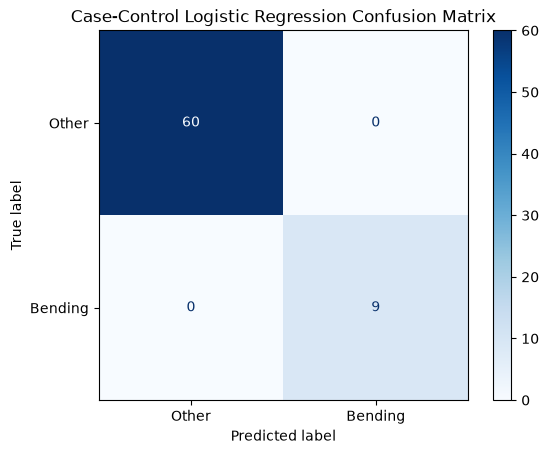

Accuracy: 1.0


In [42]:
cc_cm = confusion_matrix(y_train, adjusted_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cc_cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

print("Accuracy:", accuracy_score(y_train, adjusted_pred))

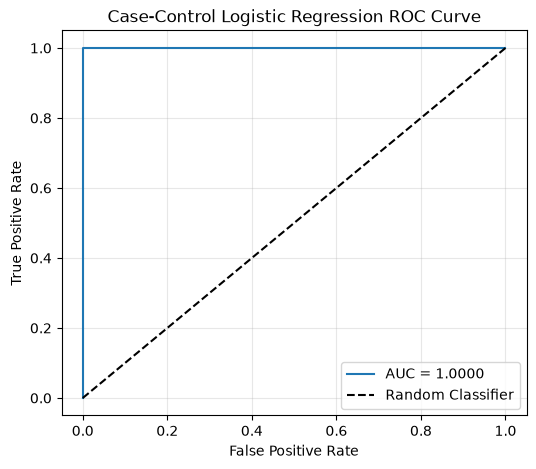

Case-Control AUC: 1.0000


In [43]:
cc_fpr, cc_tpr, _ = roc_curve(y_train, adjusted_prob)
cc_auc = roc_auc_score(y_train, adjusted_prob)

plt.figure(figsize=(6, 5))

plt.plot(cc_fpr, cc_tpr, label=f"AUC = {cc_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Case-Control AUC: {cc_auc:.4f}")

In [44]:
assert len(X_balanced) == 18
assert y_balanced.sum() == 9
assert cc_cm.shape == (2, 2)
assert len(adjusted_prob) == 69
assert np.all((adjusted_prob >= 0) & (adjusted_prob <= 1))
assert 0 <= cc_auc <= 1

print("Case-control evaluation verified successfully!")

Case-control evaluation verified successfully!


**Class Imbalance and Case-Control Sampling**

The training data is imbalanced, with 60 non-bending instances and only 9 bending instances. To address this, I used random undersampling to create a balanced dataset with 9 instances from each class.

After fitting logistic regression, I adjusted the predicted probabilities to account for the original class proportions. The model achieved 100% training accuracy and an AUC of 1.0, although these results may be optimistic because they were evaluated on the training data.

### 2(b)i — L1-Penalized Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, StratifiedKFold

def create_l1_pipeline(C):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            l1_ratio=1.0,
            C=C,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

In [46]:
C_values = np.logspace(-3, 3, 10)

l1_results = []

for l in range(1, 21):
    X = X_by_l[l]

    for C in C_values:
        pipeline = create_l1_pipeline(C)

        scores = cross_val_score(
            pipeline,
            X,
            y_train,
            cv=cv,
            scoring="accuracy",
            error_score="raise"
        )

        l1_results.append({
            "l": l,
            "C": C,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Completed l = {l}/20")

l1_results_df = pd.DataFrame(l1_results)

display(
    l1_results_df.sort_values(
        "Mean CV Accuracy",
        ascending=False
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20


,l,C,Mean CV Accuracy,CV Std
98,10,215.443469,0.971429,0.034993
116,12,10.000000,0.971429,0.034993
16,2,10.000000,0.971429,0.034993
115,12,2.154435,0.971429,0.034993
197,20,46.415888,0.971429,0.034993
8,1,215.443469,0.971429,0.034993
9,1,1000.000000,0.971429,0.034993
5,1,2.154435,0.971429,0.034993
198,20,215.443469,0.971429,0.034993
19,2,1000.000000,0.957143,0.057143


In [47]:
best_l1_row = l1_results_df.sort_values(
    ["Mean CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).iloc[0]

best_l_l1 = int(best_l1_row["l"])
best_C_l1 = float(best_l1_row["C"])
best_l1_cv_accuracy = best_l1_row["Mean CV Accuracy"]

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print(f"Best CV accuracy: {best_l1_cv_accuracy:.4f}")

Best l: 1
Best C: 2.154434690031882
Best CV accuracy: 0.9714


In [48]:
X_train_l1 = X_by_l[best_l_l1]

final_l1_pipeline = create_l1_pipeline(best_C_l1)
final_l1_pipeline.fit(X_train_l1, y_train)

l1_classifier = final_l1_pipeline.named_steps["classifier"]

selected_l1_features = X_train_l1.columns[
    np.abs(l1_classifier.coef_[0]) > 1e-8
]

print("Selected features:", len(selected_l1_features))
print("Total features:", X_train_l1.shape[1])

l1_coef_df = pd.DataFrame({
    "Feature": X_train_l1.columns,
    "Coefficient": l1_classifier.coef_[0]
})

display(
    l1_coef_df[
        l1_coef_df["Coefficient"].abs() > 1e-8
    ]
)

Selected features: 8
Total features: 42


,Feature,Coefficient
6,q3_1_1,-0.716592
8,max2_1,-0.114646
19,q1_3_1,-0.422770
26,q1_4_1,-0.373934
28,min5_1,1.685013
29,max5_1,2.376285
33,q1_5_1,0.077496
40,q1_6_1,-0.587154


In [49]:
assert len(l1_results_df) == 200
assert 1 <= best_l_l1 <= 20
assert best_C_l1 > 0
assert 0 <= best_l1_cv_accuracy <= 1
assert X_train_l1.shape == (69, 42 * best_l_l1)

print("L1 model selection verified successfully!")

L1 model selection verified successfully!


### 2(b)ii — Comparing L1 Regularization and RFE

The RFE model performed slightly better, achieving 98.57% cross-validation accuracy compared to 97.14% for L1 regularization. RFE selected 3 features, while L1 selected 8.

L1 regularization was easier to implement because it automatically selects features by shrinking some coefficients to zero. RFE requires testing different numbers of features and repeatedly fitting the model.

### 2(c)i — Multiclass Classification Using L1-Penalized Logistic Regression

In [50]:
activity_names = [
    "bending1", "bending2", "cycling",
    "lying", "sitting", "standing", "walking"
]

y_train_multi = np.array([
    file.parent.name for file in train_files
])

y_test_multi = np.array([
    file.parent.name for file in test_files
])

print("Training class counts:")
print(pd.Series(y_train_multi).value_counts().sort_index())

print("\nTesting class counts:")
print(pd.Series(y_test_multi).value_counts().sort_index())

Training class counts:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

Testing class counts:
bending1    2
bending2    2
cycling     3
lying       3
sitting     3
standing    3
walking     3
Name: count, dtype: int64


In [51]:
def create_multiclass_pipeline(C):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            l1_ratio=1.0,
            C=C,
            solver="saga",
            max_iter=10000,
            tol=1e-3,
            random_state=42
        ))
    ])

In [52]:
multi_results = []

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

for l in range(1, 21):
    X = X_by_l[l]

    for C in C_values:
        pipeline = create_multiclass_pipeline(C)

        scores = cross_val_score(
            pipeline,
            X,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy",
            error_score="raise"
        )

        multi_results.append({
            "l": l,
            "C": C,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Completed l = {l}/20")

multi_results_df = pd.DataFrame(multi_results)

display(
    multi_results_df.sort_values(
        "Mean CV Accuracy",
        ascending=False
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20


,l,C,Mean CV Accuracy,CV Std
19,2,1000.000000,0.914216,0.046697
18,2,215.443469,0.914216,0.046697
17,2,46.415888,0.899510,0.045127
7,1,46.415888,0.898693,0.048362
8,1,215.443469,0.898693,0.048362
9,1,1000.000000,0.898693,0.048362
57,6,46.415888,0.897876,0.049528
59,6,1000.000000,0.897876,0.049528
58,6,215.443469,0.897876,0.049528
16,2,10.000000,0.884804,0.056479


In [53]:
best_multi_row = multi_results_df.sort_values(
    ["Mean CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).iloc[0]

best_l_multi = int(best_multi_row["l"])
best_C_multi = float(best_multi_row["C"])
best_multi_cv_accuracy = best_multi_row["Mean CV Accuracy"]

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print(f"Best CV accuracy: {best_multi_cv_accuracy:.4f}")

Best l: 2
Best C: 215.44346900318823
Best CV accuracy: 0.9142


In [54]:
X_train_multi = X_by_l[best_l_multi]

final_multi_pipeline = create_multiclass_pipeline(best_C_multi)
final_multi_pipeline.fit(X_train_multi, y_train_multi)

print("Multiclass model trained successfully!")

Multiclass model trained successfully!


In [55]:
assert len(y_train_multi) == 69
assert len(y_test_multi) == 19
assert len(np.unique(y_train_multi)) == 7
assert len(multi_results_df) == 200
assert X_train_multi.shape == (69, 42 * best_l_multi)
assert 0 <= best_multi_cv_accuracy <= 1

print("Multiclass model selection verified successfully!")

Multiclass model selection verified successfully!


In [56]:
X_test_multi = pd.DataFrame([
    extract_l_features(sensor_data, best_l_multi)
    for sensor_data in sensor_test
])

X_test_multi = X_test_multi[X_train_multi.columns]

print("Test feature shape:", X_test_multi.shape)
print("Test instances:", len(y_test_multi))

Test feature shape: (19, 84)
Test instances: 19


In [57]:
multi_test_pred = final_multi_pipeline.predict(X_test_multi)
multi_test_prob = final_multi_pipeline.predict_proba(X_test_multi)

multi_test_accuracy = accuracy_score(y_test_multi, multi_test_pred)
multi_test_error = 1 - multi_test_accuracy

print(f"Test accuracy: {multi_test_accuracy:.4f}")
print(f"Test error: {multi_test_error:.4f}")

Test accuracy: 0.8421
Test error: 0.1579


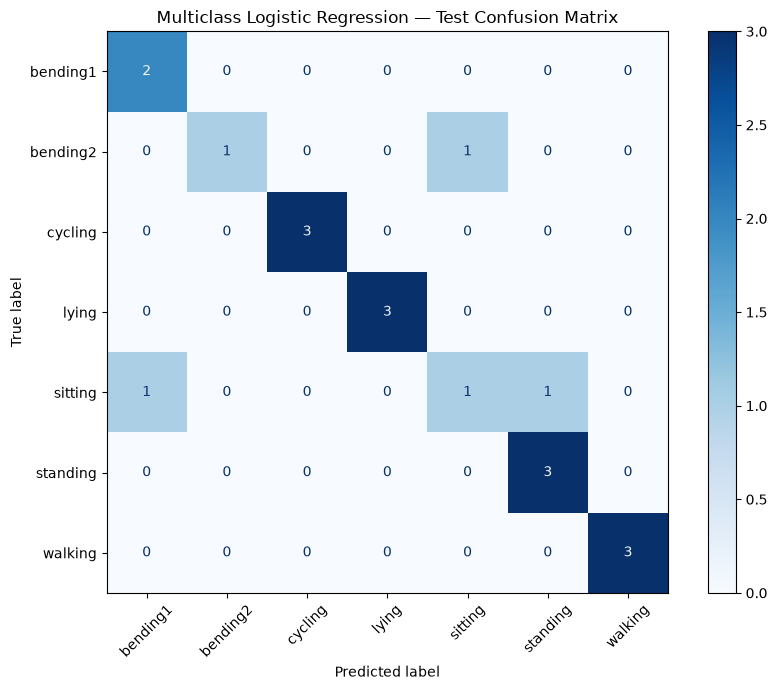

In [58]:
multi_cm = confusion_matrix(
    y_test_multi,
    multi_test_pred,
    labels=activity_names
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=activity_names
).plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("Multiclass Logistic Regression — Test Confusion Matrix")
plt.tight_layout()
plt.show()

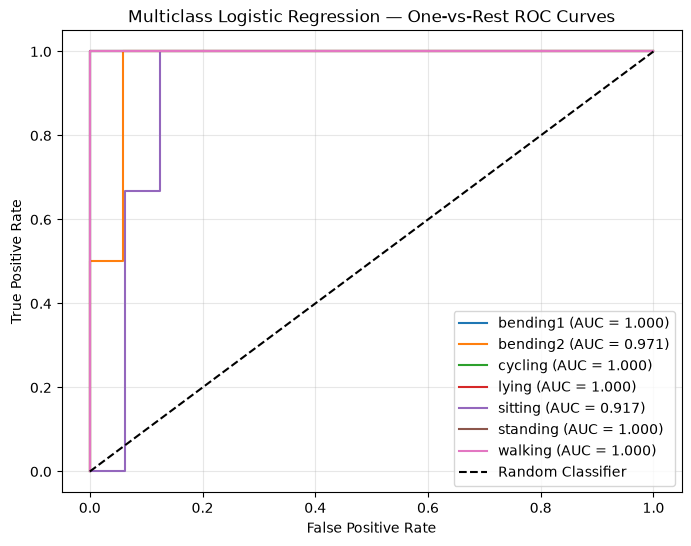

In [59]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

model_classes = final_multi_pipeline.named_steps["classifier"].classes_

y_test_bin = label_binarize(
    y_test_multi,
    classes=model_classes
)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(model_classes):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        multi_test_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{activity} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression — One-vs-Rest ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [60]:
assert X_test_multi.shape == (19, 84)
assert len(multi_test_pred) == 19
assert multi_cm.shape == (7, 7)
assert multi_test_prob.shape == (19, 7)
assert 0 <= multi_test_accuracy <= 1
assert 0 <= multi_test_error <= 1

print("Multiclass test evaluation verified successfully!")

Multiclass test evaluation verified successfully!


### 2(c)ii — Multiclass Classification Using Naive Bayes

In [61]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

In [62]:
def create_nb_pipeline(model_type):
    if model_type == "Gaussian":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", GaussianNB())
        ])

    elif model_type == "Multinomial":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", MinMaxScaler()),
            ("classifier", MultinomialNB())
        ])

In [63]:
nb_results = []

for model_type in ["Gaussian", "Multinomial"]:
    for l in range(1, 21):
        pipeline = create_nb_pipeline(model_type)

        scores = cross_val_score(
            pipeline,
            X_by_l[l],
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy",
            error_score="raise"
        )

        nb_results.append({
            "Model": model_type,
            "l": l,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Completed {model_type} Naive Bayes")

nb_results_df = pd.DataFrame(nb_results)

display(
    nb_results_df.sort_values(
        ["Model", "Mean CV Accuracy"],
        ascending=[True, False]
    ).groupby("Model").head(5)
)

Completed Gaussian Naive Bayes
Completed Multinomial Naive Bayes


,Model,l,Mean CV Accuracy,CV Std
0,Gaussian,1,0.856209,0.061487
1,Gaussian,2,0.796569,0.098376
7,Gaussian,8,0.693627,0.080659
6,Gaussian,7,0.679739,0.123752
3,Gaussian,4,0.665033,0.080895
21,Multinomial,2,0.767157,0.094641
24,Multinomial,5,0.767157,0.094641
25,Multinomial,6,0.766340,0.151274
26,Multinomial,7,0.766340,0.095095
28,Multinomial,9,0.752451,0.106808


In [64]:
best_nb_results = (
    nb_results_df.sort_values(
        ["Mean CV Accuracy", "l"],
        ascending=[False, True]
    )
    .groupby("Model")
    .first()
    .reset_index()
)

display(best_nb_results)

,Model,l,Mean CV Accuracy,CV Std
0,Gaussian,1,0.856209,0.061487
1,Multinomial,2,0.767157,0.094641


In [65]:
nb_test_results = []
nb_models = {}

for _, row in best_nb_results.iterrows():
    model_type = row["Model"]
    best_l_nb = int(row["l"])

    X_train_nb = X_by_l[best_l_nb]

    X_test_nb = pd.DataFrame([
        extract_l_features(sensor_data, best_l_nb)
        for sensor_data in sensor_test
    ])

    X_test_nb = X_test_nb[X_train_nb.columns]

    model = create_nb_pipeline(model_type)
    model.fit(X_train_nb, y_train_multi)

    predictions = model.predict(X_test_nb)

    accuracy = accuracy_score(y_test_multi, predictions)
    error = 1 - accuracy

    nb_models[model_type] = model

    nb_test_results.append({
        "Model": model_type,
        "Best l": best_l_nb,
        "CV Accuracy": row["Mean CV Accuracy"],
        "Test Accuracy": accuracy,
        "Test Error": error
    })

nb_test_df = pd.DataFrame(nb_test_results)

display(nb_test_df.round(4))

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,Gaussian,1,0.8562,0.8947,0.1053
1,Multinomial,2,0.7672,0.7895,0.2105


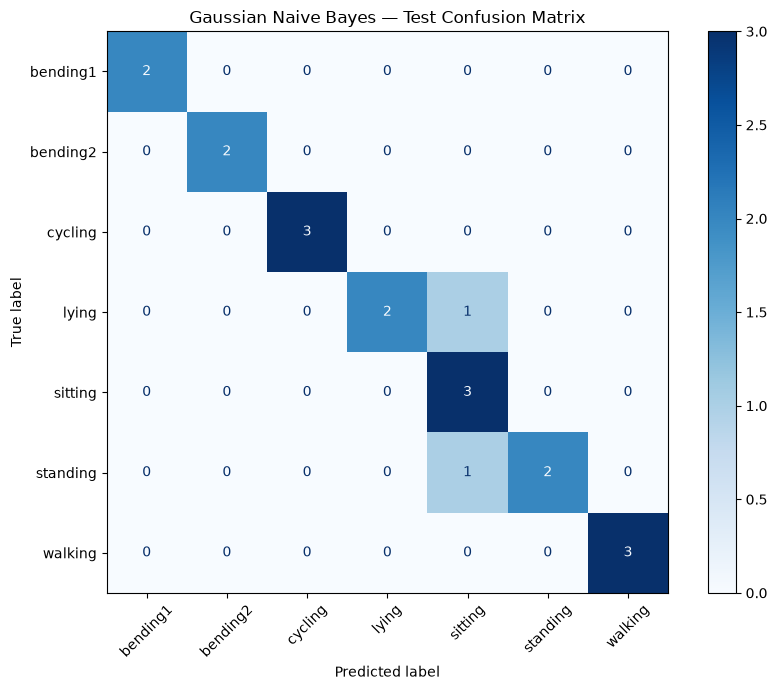

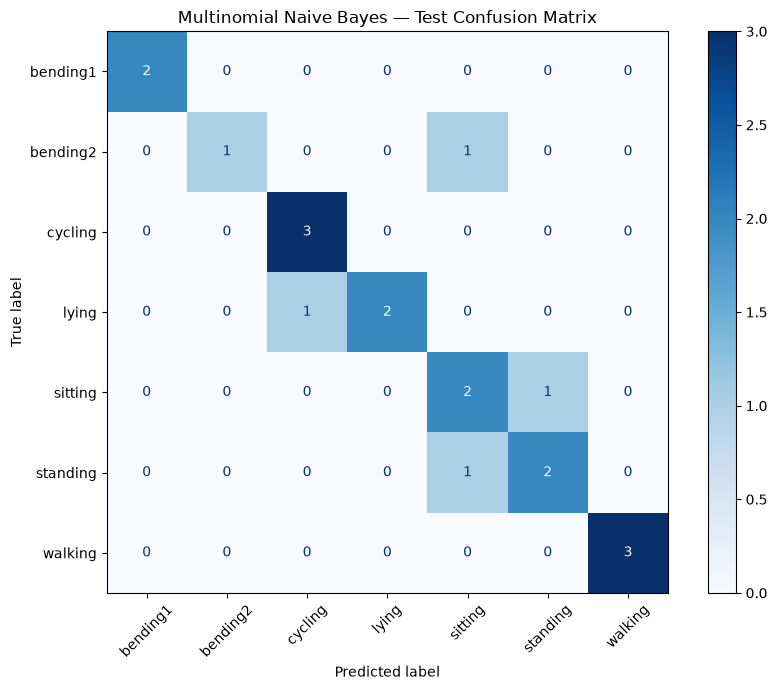

In [66]:
for _, row in best_nb_results.iterrows():
    model_type = row["Model"]
    best_l_nb = int(row["l"])

    X_train_nb = X_by_l[best_l_nb]

    X_test_nb = pd.DataFrame([
        extract_l_features(sensor_data, best_l_nb)
        for sensor_data in sensor_test
    ])

    X_test_nb = X_test_nb[X_train_nb.columns]

    predictions = nb_models[model_type].predict(X_test_nb)

    cm_nb = confusion_matrix(
        y_test_multi,
        predictions,
        labels=activity_names
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_nb,
        display_labels=activity_names
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45
    )

    plt.title(f"{model_type} Naive Bayes — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [67]:
assert len(nb_results_df) == 40
assert len(best_nb_results) == 2
assert len(nb_test_df) == 2

assert nb_test_df["Test Accuracy"].between(0, 1).all()
assert nb_test_df["Test Error"].between(0, 1).all()

print("Naive Bayes evaluation verified successfully!")

Naive Bayes evaluation verified successfully!


### 2(c)iii — Comparison of Multiclass Classification Methods

In [68]:
comparison_df = pd.concat([
    pd.DataFrame([{
        "Model": "L1 Logistic Regression",
        "CV Accuracy": best_multi_cv_accuracy,
        "Test Accuracy": multi_test_accuracy,
        "Test Error": multi_test_error
    }]),
    nb_test_df[[
        "Model", "CV Accuracy", "Test Accuracy", "Test Error"
    ]]
], ignore_index=True)

comparison_df = comparison_df.sort_values(
    "Test Accuracy", ascending=False
)

display(comparison_df.round(4))

,Model,CV Accuracy,Test Accuracy,Test Error
1,Gaussian,0.8562,0.8947,0.1053
0,L1 Logistic Regression,0.9142,0.8421,0.1579
2,Multinomial,0.7672,0.7895,0.2105


In [69]:
best_model = comparison_df.iloc[0]

print("Best model:", best_model["Model"])
print(f"Test accuracy: {best_model['Test Accuracy']:.4f}")
print(f"Test error: {best_model['Test Error']:.4f}")

Best model: Gaussian
Test accuracy: 0.8947
Test error: 0.1053


In [70]:
assert len(comparison_df) == 3
assert comparison_df["Test Accuracy"].between(0, 1).all()
assert comparison_df["Test Error"].between(0, 1).all()

print("Multiclass model comparison verified successfully!")

Multiclass model comparison verified successfully!


**Conclusion:**

Gaussian Naive Bayes performed the best on the test set, achieving 89.47% accuracy and a 10.53% error rate. L1 logistic regression came second with 84.21% accuracy, followed by Multinomial Naive Bayes at 78.95%.

Although L1 logistic regression had the highest cross-validation accuracy, Gaussian Naive Bayes performed better on the unseen test data.


### Problem 3 — ISLR 4.8.3

For QDA, we assume each class follows a normal distribution:

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
$$

Using Bayes' theorem, the discriminant function is:

$$
\delta_k(x)=\log(\pi_k)-\frac{1}{2}\log(\sigma_k^2)-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

Expanding the squared term:

$$
\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k x}{\sigma_k^2}-\frac{\mu_k^2}{2\sigma_k^2}-\frac{1}{2}\log(\sigma_k^2)+\log(\pi_k)
$$

Since each class can have a different variance, the coefficient of the squared term differs across classes. When comparing two classes, these terms generally do not cancel.

Therefore, **the decision boundary is quadratic rather than linear** when class variances differ.



### Problem 4 — ISLR 4.8.7

We are given:

- Mean profit for companies that issue dividends: $\mu_{\text{Yes}} = 10$
- Mean profit for companies that do not: $\mu_{\text{No}} = 0$
- Variance for both groups: $\sigma^2 = 36$
- Prior probabilities: $P(\text{Yes}) = 0.8$ and $P(\text{No}) = 0.2$
- Observed profit: $X = 4$

Using Bayes' theorem:

$$
P(\text{Yes}\mid X=4)=\frac{0.8f_{\text{Yes}}(4)}{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}
$$

Since both groups follow normal distributions with variance 36:

$$
f_{\text{Yes}}(4)=\frac{1}{6\sqrt{2\pi}}e^{-\frac{(4-10)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-0.5}
$$

$$
f_{\text{No}}(4)=\frac{1}{6\sqrt{2\pi}}e^{-\frac{(4-0)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-2/9}
$$

Substituting and canceling the common factor:

$$
P(\text{Yes}\mid X=4)=\frac{0.8e^{-0.5}}{0.8e^{-0.5}+0.2e^{-2/9}}
\approx 0.752
$$

**Conclusion:** The probability that the company will issue a dividend, given a 4% profit last year, is approximately **75.2%**.
